# EfficientNet_02: EfficientNet-B0 on the grouped split (34 species, by recording)

**Recipe (2025, unchanged):** ImageNet EfficientNet-B0, full fine-tuning, batch 16, AdamW lr 1e-3 / wd 1e-4,
class-weighted cross-entropy, ReduceLROnPlateau (×0.5, patience 2), grad clip 1.0, max 10 epochs,
early stopping patience 3, best checkpoint = lowest val loss. Additions: seed 42, mixed precision on GPU.

**Input:** 128-mel spectrogram, first 400 frames (~4.65 s at 44 kHz).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config
print("data root:", config.DATA_ROOT)
import pandas as pd, matplotlib.pyplot as plt, torch
RUN, SPLIT, SPLIT_DIR = "EfficientNet_02", "grouped", config.GROUPED_SPLIT_DIR
print(RUN, SPLIT, SPLIT_DIR, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

data root: D:\UNI&WORK\Watkins


EfficientNet_02 grouped D:\UNI&WORK\Watkins\Annotations\grouped_34 | GPU: NVIDIA GeForce RTX 5050 Laptop GPU


## Data check

In [2]:
parts = {s: pd.read_csv(SPLIT_DIR / f"{s}.csv") for s in ["train", "val", "test"]}
print({s: len(p) for s, p in parts.items()}, "| species:", parts["train"].category.nunique(),
      "| recordings shared train/test:", len(set(parts["train"].recording) & set(parts["test"].recording)))

{'train': 9502, 'val': 2102, 'test': 2057} | species: 34 | recordings shared train/test: 0


## Train

In [3]:
from src.EfficientNet.train import Trainer, next_checkpoint_path
ckpt = next_checkpoint_path(RUN)
trainer = Trainer(SPLIT_DIR, ckpt)
trainer.fit()

caching train.csv:   0%|          | 0/9502 [00:00<?, ?it/s]

caching train.csv: 100%|██████████| 9502/9502 [00:04<00:00, 1924.82it/s]

caching val.csv:   0%|          | 0/2102 [00:00<?, ?it/s]

caching val.csv: 100%|██████████| 2102/2102 [00:01<00:00, 1906.49it/s]

caching test.csv:   0%|          | 0/2057 [00:00<?, ?it/s]

caching test.csv: 100%|██████████| 2057/2057 [00:01<00:00, 1739.43it/s]

... (6 outputs left out)

Epoch 4/10 | train loss 0.2029 acc 96.24 | val loss 4.2850 acc 51.19 | lr 1.00e-03 | 36s


Epoch 5/10 | train loss 0.1505 acc 96.67 | val loss 4.1418 acc 48.62 | lr 1.00e-03 | 36s


  early stopping (no val-loss improvement for 3 epochs)


Training finished.


,epoch,train_loss,val_loss,train_acc,val_acc,lr,seconds
0,1,1.338061,3.953149,72.1743,36.3463,0.001,116.5
1,2,0.559642,3.607578,89.4654,39.4386,0.001,35.4
2,3,0.310029,4.806616,94.1591,40.4377,0.001,34.9
3,4,0.202922,4.284989,96.2429,51.1893,0.001,35.6
4,5,0.150484,4.141764,96.6744,48.6204,0.001,36.5


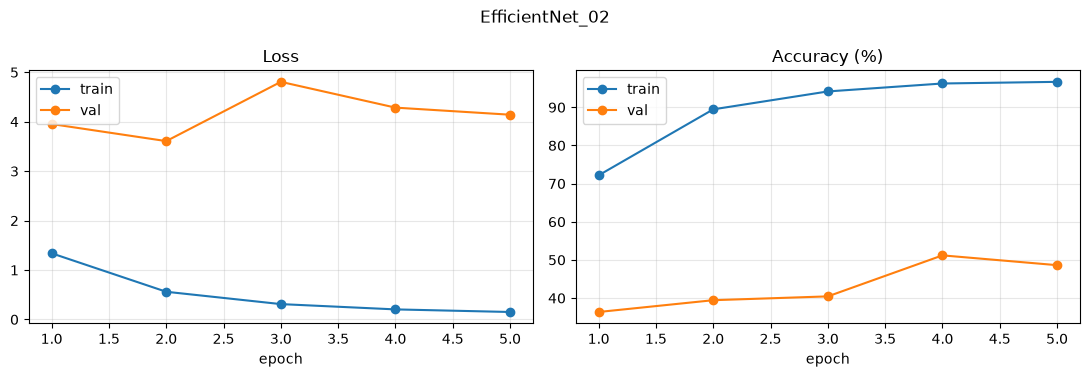

In [4]:
from src.plot_analysis import plot_learning_curves
config.EVAL_DIR.mkdir(parents=True, exist_ok=True)
plot_learning_curves(trainer.history_path, RUN, config.EVAL_DIR / f"learning_curves_{RUN}.png");
pd.read_csv(trainer.history_path)

## Test-set evaluation (best checkpoint)

In [5]:
from src.evaluate import predict, save_evaluation
y, yp, probs = predict(trainer.model, trainer.test_loader, trainer.device)
m = save_evaluation(RUN, SPLIT, trainer.classes, trainer.test_loader.dataset.filenames, y, yp, probs)
pd.Series(m).round(4)

accuracy              0.6062
precision_macro       0.4720
recall_macro          0.4777
f1_macro              0.4357
precision_weighted    0.6930
recall_weighted       0.6062
f1_weighted           0.6100
dtype: float64

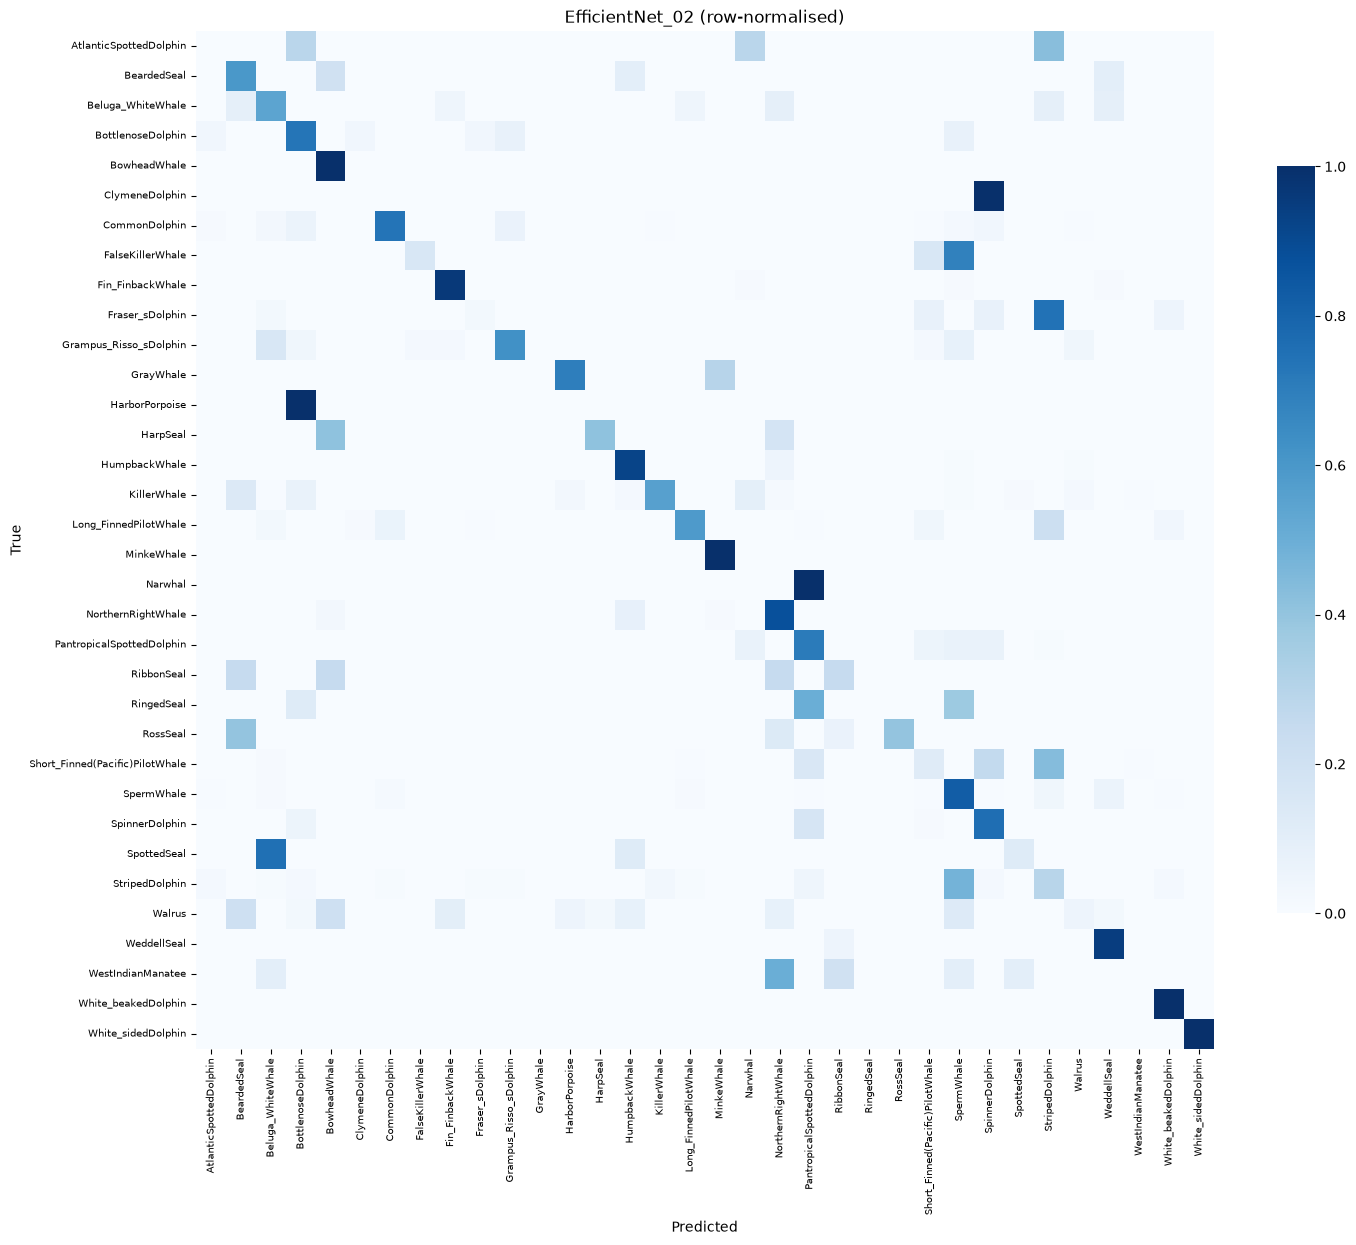

In [6]:
from src.plot_analysis import plot_confusion_matrix, plot_per_class_f1
cm = pd.read_csv(config.EVAL_DIR / f"confusion_matrix_{RUN}.csv", index_col=0).values
plot_confusion_matrix(cm, trainer.classes, f"{RUN} (row-normalised)", config.EVAL_DIR / f"confusion_matrix_{RUN}.png");

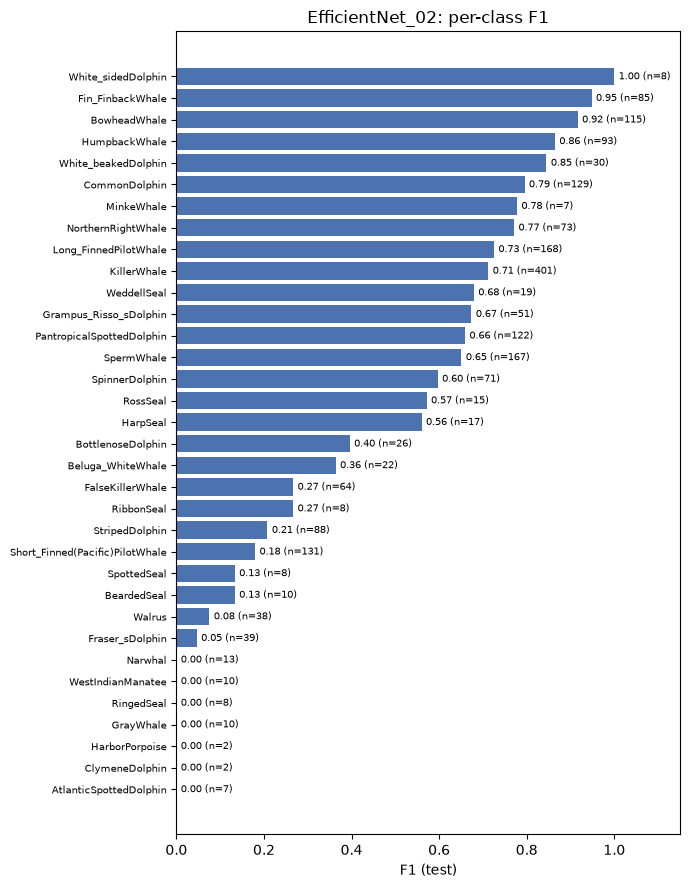

In [7]:
plot_per_class_f1(config.EVAL_DIR / f"classification_report_{RUN}.csv", f"{RUN}: per-class F1",
                  config.EVAL_DIR / f"per_class_f1_{RUN}.png");

In [8]:
rep = pd.read_csv(config.EVAL_DIR / f"classification_report_{RUN}.csv", index_col=0)
rep = rep.drop(index=["accuracy", "macro avg", "weighted avg"])
print("Hardest classes:"); rep.sort_values("f1-score").head(10).round(3)

Hardest classes:


,precision,recall,f1-score,support
AtlanticSpottedDolphin,0.000,0.000,0.000,7.0
ClymeneDolphin,0.000,0.000,0.000,2.0
HarborPorpoise,0.000,0.000,0.000,2.0
GrayWhale,0.000,0.000,0.000,10.0
RingedSeal,0.000,0.000,0.000,8.0
WestIndianManatee,0.000,0.000,0.000,10.0
Narwhal,0.000,0.000,0.000,13.0
Fraser_sDolphin,0.250,0.026,0.047,39.0
Walrus,0.133,0.053,0.075,38.0
BeardedSeal,0.075,0.600,0.133,10.0
